# Summary Statistics for Final Datasets
This notebook loads the finalized datasets and produces summary statistics, visualizations, and data quality checks.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 200)
sns.set_theme(style='whitegrid')

print('Setup complete')

Setup complete


In [2]:
BASE_PATH = Path('../../../XAI Evalation For IDS datasets (Explanatory Power,Actionability,Explanation Accuracy)/IDS_Datasets')
READY_PATH = BASE_PATH / 'Ready Datasets'

CIC_FINAL = READY_PATH / 'CIC_IIoT_2025_final.csv'
IDS_FINAL = READY_PATH / 'IDS2025_Balanced_final.csv'

for p in [CIC_FINAL, IDS_FINAL]:
    if not p.exists():
        raise FileNotFoundError(f'Missing finalized dataset: {p}')

df_cic = pd.read_csv(CIC_FINAL, low_memory=False)
df_ids = pd.read_csv(IDS_FINAL, low_memory=False)

print('Loaded final datasets:')
print(f'  CIC IIoT 2025: {df_cic.shape}')
print(f'  IDS2025 Balanced: {df_ids.shape}')

Loaded final datasets:
  CIC IIoT 2025: (383470, 67)
  IDS2025 Balanced: (91740, 57)


In [3]:
def summarize_basic(df: pd.DataFrame, name: str) -> dict:
    print(f'\n=== {name} ===')
    rows, cols = df.shape
    missing_total = int(df.isnull().sum().sum())
    dupes = int(df.duplicated().sum())
    numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
    categorical_cols = [c for c in df.columns if c not in numeric_cols and c != 'label']
    print(f'Rows: {rows:,} | Columns: {cols:,}')
    print(f'Numeric: {len(numeric_cols)} | Categorical: {len(categorical_cols)}')
    print(f'Missing values: {missing_total:,} | Duplicates: {dupes:,}')
    return {
        'rows': rows,
        'cols': cols,
        'numeric_cols': numeric_cols,
        'categorical_cols': categorical_cols,
        'missing_total': missing_total,
        'duplicates': dupes
    }

cic_stats = summarize_basic(df_cic, 'CIC IIoT 2025 (Final)')
ids_stats = summarize_basic(df_ids, 'IDS2025 Balanced (Final)')


=== CIC IIoT 2025 (Final) ===
Rows: 383,470 | Columns: 67
Numeric: 66 | Categorical: 0
Missing values: 0 | Duplicates: 0

=== IDS2025 Balanced (Final) ===
Rows: 91,740 | Columns: 57
Numeric: 56 | Categorical: 0
Missing values: 0 | Duplicates: 0




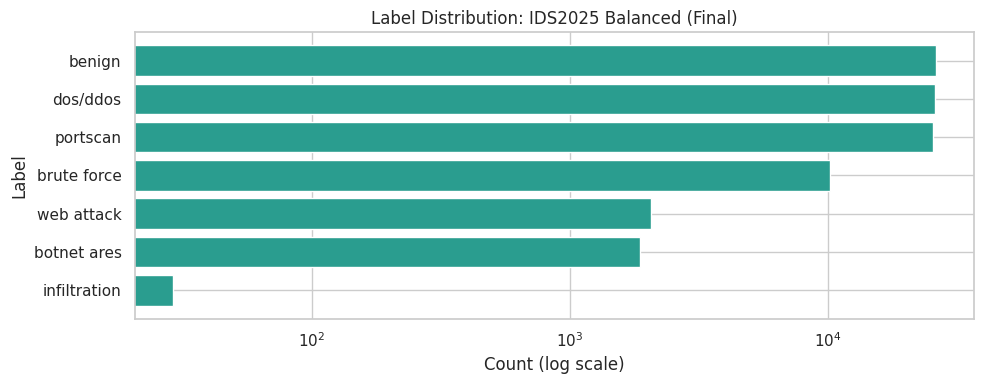

In [4]:
def plot_label_distribution(df: pd.DataFrame, name: str, top_n: int | None = None, log_scale: bool = True) -> None:
    if 'label' not in df.columns:
        print(f'Label column not found for {name}.')
        return
    counts = df['label'].value_counts()
    if top_n is not None:
        counts = counts.head(top_n)
    counts = counts.sort_values(ascending=True)
    plt.figure(figsize=(10, max(4, len(counts) * 0.25)))
    plt.barh(counts.index, counts.values, color='#2a9d8f')
    plt.title(f'Label Distribution: {name}')
    plt.xlabel('Count')
    plt.ylabel('Label')
    if log_scale:
        plt.xscale('log')
        plt.xlabel('Count (log scale)')
    plt.tight_layout()
    plt.show()

plot_label_distribution(df_cic, 'CIC IIoT 2025 (Final)', top_n=None, log_scale=True)
plot_label_distribution(df_ids, 'IDS2025 Balanced (Final)', top_n=None, log_scale=True)

In [5]:
def attack_type_breakdown(df: pd.DataFrame, name: str) -> None:
    if 'label' not in df.columns:
        print(f'Label column not found for {name}.')
        return
    labels = df['label'].astype(str)
    if labels.str.contains('attack_').any():
        attack_types = labels.str.extract(r'attack_([^_]+)')[0].fillna('benign')
    else:
        attack_types = labels
    counts = attack_types.value_counts()
    print(f'\nAttack type breakdown: {name}')
    display(counts.to_frame(name='count'))

attack_type_breakdown(df_cic, 'CIC IIoT 2025 (Final)')
attack_type_breakdown(df_ids, 'IDS2025 Balanced (Final)')


Attack type breakdown: CIC IIoT 2025 (Final)


,count
0,
benign,134070
recon,85116
dos,55442
ddos,51561
mitm,23287
malware,22624
web,6944
bruteforce,4426



Attack type breakdown: IDS2025 Balanced (Final)


,count
label,
benign,26169
dos/ddos,25992
portscan,25409
brute force,10201
web attack,2067
botnet ares,1873
infiltration,29


In [6]:
def detect_outliers_iqr(df: pd.DataFrame, numeric_cols: list, max_features: int = 20) -> pd.DataFrame:
    cols = numeric_cols[:max_features]
    rows = []
    for col in cols:
        series = df[col].dropna()
        if series.empty:
            continue
        q1 = series.quantile(0.25)
        q3 = series.quantile(0.75)
        iqr = q3 - q1
        if iqr == 0:
            outliers = 0
        else:
            lower = q1 - 1.5 * iqr
            upper = q3 + 1.5 * iqr
            outliers = int(((series < lower) | (series > upper)).sum())
        rows.append({'feature': col, 'outliers': outliers})
    return pd.DataFrame(rows).sort_values('outliers', ascending=False)

def missing_values_report(df: pd.DataFrame, name: str) -> None:
    missing = df.isnull().sum().sort_values(ascending=False)
    missing = missing[missing > 0]
    print(f'\nMissing values report: {name}')
    if len(missing) == 0:
        print('No missing values found.')
    else:
        display(missing.to_frame(name='missing'))

cic_outliers = detect_outliers_iqr(df_cic, cic_stats['numeric_cols'])
ids_outliers = detect_outliers_iqr(df_ids, ids_stats['numeric_cols'])

missing_values_report(df_cic, 'CIC IIoT 2025 (Final)')
missing_values_report(df_ids, 'IDS2025 Balanced (Final)')

print('\nTop IQR outliers (CIC IIoT):')
display(cic_outliers.head(10))
print('\nTop IQR outliers (IDS2025):')
display(ids_outliers.head(10))


Missing values report: CIC IIoT 2025 (Final)
No missing values found.

Missing values report: IDS2025 Balanced (Final)
No missing values found.

Top IQR outliers (CIC IIoT):


,feature,outliers
2,log_data_ranges_min,88988
0,log_data_ranges_avg,88373
6,log_messages_count,65896
1,log_data_ranges_max,65619
14,network_macs_dst_count,53770
15,network_macs_src_count,53770
12,network_interval_packets,42221
13,network_macs_all_count,41635
3,log_data_ranges_std_deviation,0
4,log_data_types_count,0



Top IQR outliers (IDS2025):


,feature,outliers
14,bwd_packet_length_std,20713
16,fwd_iat_mean,20505
13,bwd_packet_length_mean,20221
17,fwd_iat_std,19238
6,total_length_of_bwd_packets,18770
11,bwd_packet_length_max,18566
19,fwd_iat_min,18446
15,fwd_iat_total,18042
8,fwd_packet_length_min,17951
1,destination_port,17811


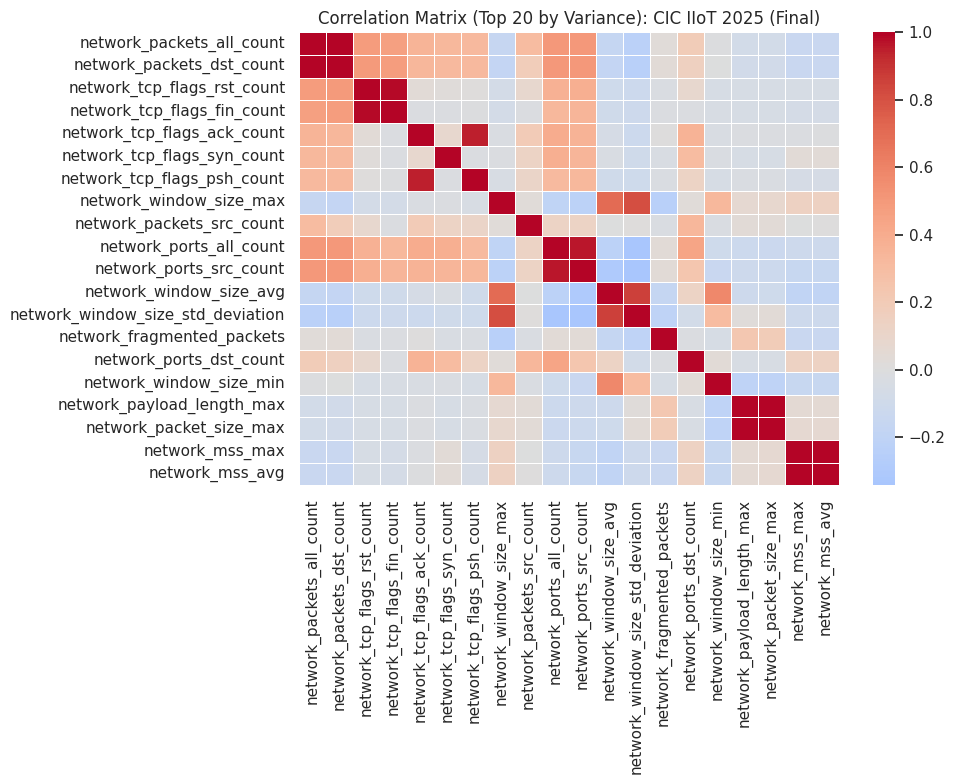

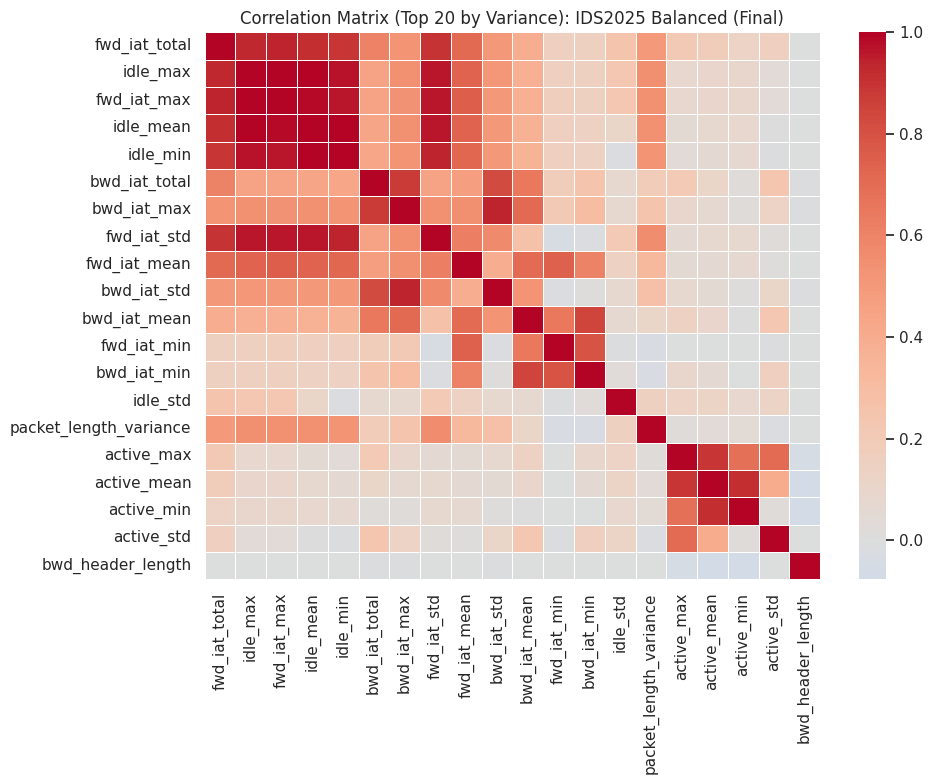

In [7]:
def correlation_heatmap(df: pd.DataFrame, name: str, max_features: int = 20) -> None:
    numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
    if not numeric_cols:
        print(f'No numeric columns for correlation: {name}')
        return
    variances = df[numeric_cols].var(numeric_only=True).sort_values(ascending=False)
    top_cols = variances.head(max_features).index.tolist()
    corr = df[top_cols].corr()
    plt.figure(figsize=(10, 8))
    sns.heatmap(corr, cmap='coolwarm', center=0, linewidths=0.5)
    plt.title(f'Correlation Matrix (Top {max_features} by Variance): {name}')
    plt.tight_layout()
    plt.show()

correlation_heatmap(df_cic, 'CIC IIoT 2025 (Final)')
correlation_heatmap(df_ids, 'IDS2025 Balanced (Final)')

In [8]:
def data_quality_issues(df: pd.DataFrame, name: str) -> None:
    rows, _ = df.shape
    dupes = int(df.duplicated().sum())
    missing_total = int(df.isnull().sum().sum())
    constant_cols = []
    near_constant_cols = []
    for col in df.columns:
        counts = df[col].value_counts(dropna=False)
        if len(counts) <= 1:
            constant_cols.append(col)
        else:
            if counts.iloc[0] / rows >= 0.99:
                near_constant_cols.append(col)
    print(f'\nData quality issues: {name}')
    print(f'Duplicates: {dupes} | Missing values: {missing_total}')
    print(f'Constant columns: {len(constant_cols)} | Near-constant columns: {len(near_constant_cols)}')
    if constant_cols:
        print('Constant columns (first 10):', constant_cols[:10])
    if near_constant_cols:
        print('Near-constant columns (first 10):', near_constant_cols[:10])

data_quality_issues(df_cic, 'CIC IIoT 2025 (Final)')
data_quality_issues(df_ids, 'IDS2025 Balanced (Final)')


Data quality issues: CIC IIoT 2025 (Final)
Duplicates: 0 | Missing values: 0
Constant columns: 0 | Near-constant columns: 0

Data quality issues: IDS2025 Balanced (Final)
Duplicates: 0 | Missing values: 0
Constant columns: 0 | Near-constant columns: 0
